# XGBoost: interpretazione

Il modello finale viene caricato da MLflow così come l'ha salvato `python -m churn.train_xgboost` (lo stesso che usa
il DAG): qui non si riaddestra nulla. Tutto è calcolato sui 20.000 clienti di **hold-out**, mai usati per nessuna
scelta.

1. **Importanza SHAP**: quali variabili muovono il rischio, e quanto.
2. **Dependence plot**: la forma dell'effetto delle 6 variabili numeriche più importanti.
3. **Un cliente**: da dove viene il suo score (waterfall).
4. **La soglia**: recall massima con precision ≥ 0.6.
5. **Risultati sull'hold-out**: metriche e matrici di confusione, prima e dopo il cambio di soglia.
6. **Con un budget di chiamate**: quanti churner trovo chiamando i clienti più a rischio.

> **Nota: il campione è bilanciato** (~50% di churn: 49.6% sul train). Precision, PR-AUC e Brier score
> dipendono dalla prevalenza, quindi qui non rappresentano quella reale. In produzione, dove il churn è molto più
> raro, alla stessa soglia la precision sarebbe più bassa (più falsi allarmi per ogni churner trovato) e le
> probabilità andrebbero ricalibrate sul tasso reale. Recall (a soglia fissa) e ROC-AUC invece non dipendono dalla prevalenza.

In [1]:
import os
import warnings

# Quieter outputs: no MLflow download bars or hints, no notice about the missing notebook progress widget.
os.environ["MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR"] = "false"
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", message="Found unknown categories")
# A variable that is constant on the test set has no direction (Spearman undefined): expected, it stays unsigned.
warnings.filterwarnings("ignore", message="An input array is constant")

In [2]:
import mlflow
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

from churn.config import ROOT, load_config
from churn.data import load_raw, split
from churn.model import metrics, shap_importance, split_xy, tree_contributions
from churn.plots import (
    plot_dependence,
    plot_importance,
    plot_pr_curve,
    plot_waterfall,
    set_style,
)
from churn.train_logistic import setup_mlflow

cfg = load_config()
set_style()
setup_mlflow(cfg)

# The most recent final run of the experiment; its model is loaded as saved.
run = mlflow.search_runs(experiment_names=[cfg["mlflow"]["experiment"]],
                         filter_string="tags.mlflow.runName = 'xgb_final'",
                         order_by=["start_time DESC"], max_results=1).iloc[0]
pipe = mlflow.sklearn.load_model(f"runs:/{run.run_id}/model")
threshold = float(run["params.threshold"])
run[["params.feature_engineering", "params.threshold", "metrics.test_pr_auc", "metrics.test_roc_auc",
     "metrics.test_brier", "metrics.test_precision", "metrics.test_recall", "metrics.test_f1"]]

params.feature_engineering                  True
params.threshold              0.4305405020713806
metrics.test_pr_auc                     0.691313
metrics.test_roc_auc                    0.699086
metrics.test_brier                      0.219148
metrics.test_precision                  0.598191
metrics.test_recall                     0.780569
metrics.test_f1                         0.677318
Name: 0, dtype: object

In [3]:
# The same split as the training script, so the same hold-out customers.
_, test = split(load_raw(ROOT / cfg["paths"]["raw_data"]), cfg["target"], cfg["test_size"], cfg["seed"])
X_test, y_test = split_xy(test, cfg)
proba = pipe.predict_proba(X_test)[:, 1]
# SHAP value of every variable for every customer, and the average log-odds they start from.
contrib, base = tree_contributions(pipe, X_test)
values = pipe[:-2].transform(X_test)  # the model's inputs before encoding: cleaned values + engineered features

## 1. Quali variabili contano: importanza SHAP

**Cos'è SHAP.** Per ogni cliente il modello produce un log-odds di churn. SHAP (TreeSHAP esatto, calcolato da
XGBoost stesso) lo scompone in una somma:

*log-odds del cliente = log-odds del cliente medio + un contributo per ogni variabile.*

Il contributo di una variabile dice di quanto il suo valore, per quel cliente, sposta il rischio rispetto al cliente
medio (positivo = più rischio). Le colonne one-hot di una variabile categorica sono sommate nella variabile.

**Il criterio di importanza** è il contributo **medio in valore assoluto** sui 20.000 clienti di test: di quanto, in
media, quella variabile sposta il log-odds. Unità: log-odds; +0.5 ≈ odds ×1.65, +1 ≈ odds ×2.7.

**Come si legge.** Barre ordinate dalla più importante. **(+)**: valori alti → più rischio; **(−)**: valori alti →
meno rischio (|Spearman tra valore e contributo| ≥ 0.5). Nessun segno: l'effetto non va in una sola direzione (o la
variabile è categorica), e la sua forma è nel dependence plot.

SHAP spiega il modello, non il mondo: associazione, non causalità.

99 input variables; the top 11 carry 50% of the total importance


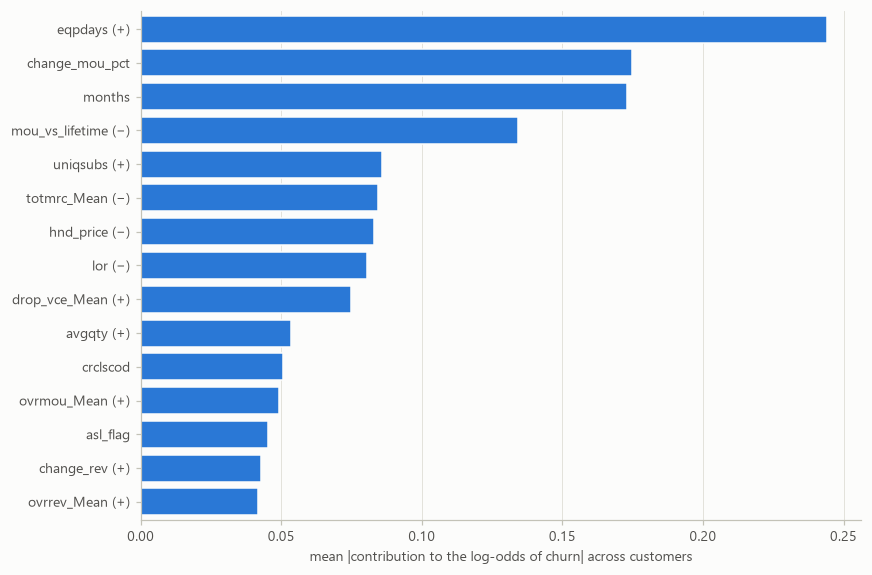

In [4]:
imp = shap_importance(contrib, values.select_dtypes("number"), cfg["shap"]["monotonic_rho"])
share = imp["importance"].cumsum() / imp["importance"].sum()
print(f"{len(imp)} input variables; the top {int((share < 0.5).sum()) + 1} carry 50% of the total importance")
fig = plot_importance(imp, 15)

**Cosa dice.**
- **Quattro variabili guidano**: età del telefono (`eqpdays`, 0.24), calo d'uso recente (`change_mou_pct`, 0.18),
  anzianità (`months`, 0.17), uso rispetto alla propria media di sempre (`mou_vs_lifetime`, 0.13).
- Poi, quasi a pari merito (0.075–0.086): più linee in famiglia (`uniqsubs`, +), canone mensile (`totmrc_Mean`, −),
  prezzo del telefono (`hnd_price`, −), anni allo stesso indirizzo (`lor`, −), chiamate cadute (`drop_vce_Mean`, +).
- Le prime 11 variabili su 99 portano metà dell'importanza; le due feature costruite sono 2ª e 4ª.
- `change_mou_pct` e `months` non hanno segno non perché contino poco, ma perché il loro effetto ha una forma
  (sezione 2).
- Le stesse quattro variabili sono in testa anche in un XGBoost precedente dell'esplorazione (tuning e feature
  diversi), dove restavano ai primi quattro posti in tutti e 5 i fold: i driver non dipendono dal modello.

## 2. Dependence plot: la forma dell'effetto

Le 6 variabili numeriche più importanti, nell'ordine del grafico precedente. Ogni punto è un cliente di test: asse x
il valore della variabile (tagliato al 1°–99° percentile), asse y il suo contributo SHAP. La linea nera è il
contributo medio per fascia: **sopra lo zero la variabile alza il rischio, sotto lo abbassa**. L'asse y è lo stesso
per tutti i pannelli, quindi si confronta anche la forza. Dove, a parità di x, i punti si allargano in verticale,
l'effetto dipende anche dalle altre variabili (interazioni).

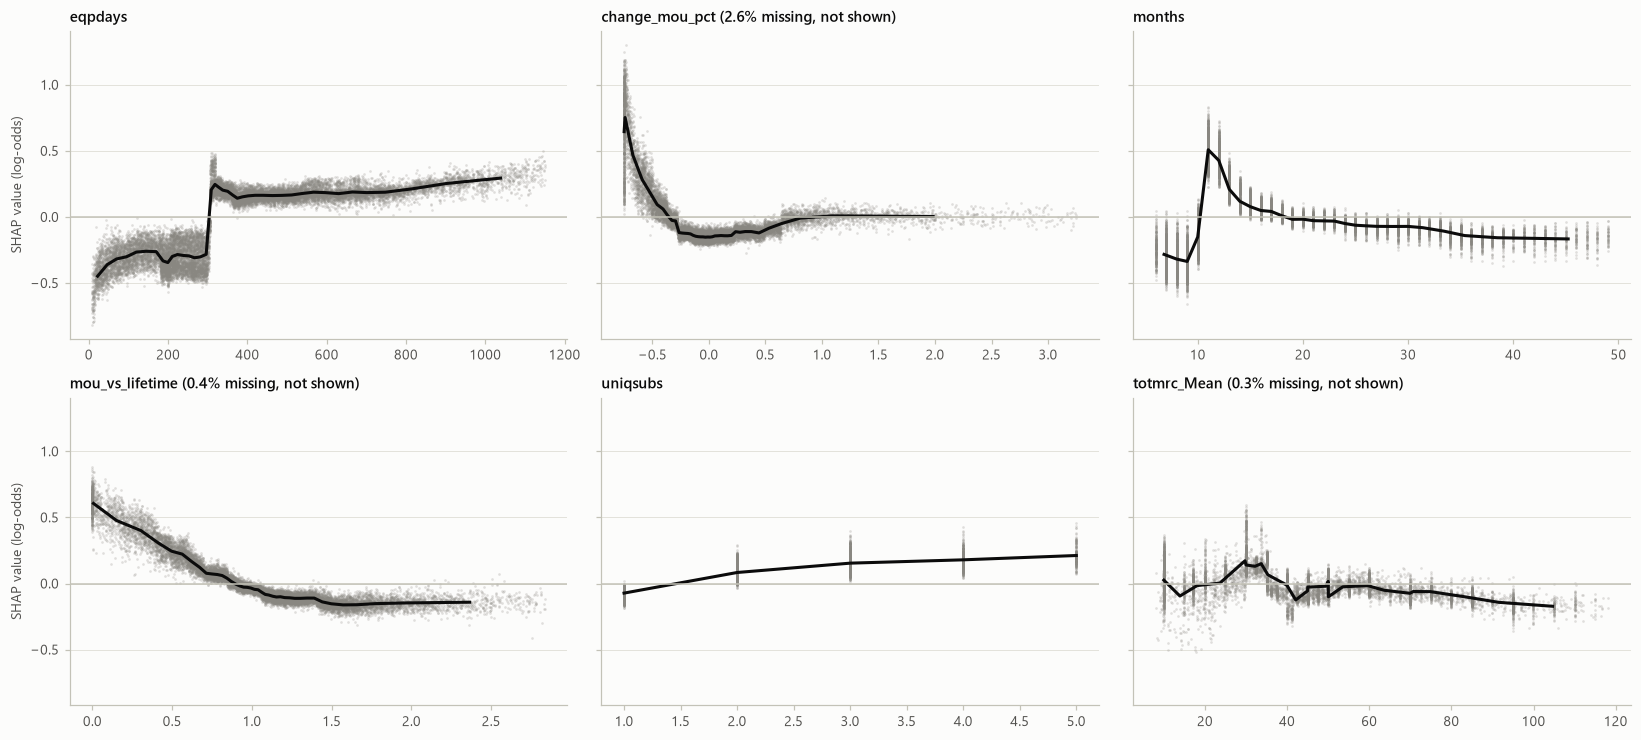

In [5]:
numeric = [v for v in imp.index if v in values.select_dtypes("number")][:6]
fig = plot_dependence(contrib, values, numeric, ncols=3)

**Cosa dice.**
- **`eqpdays`: un gradino a 300 giorni.** Sotto, il telefono nuovo protegge (da −0.45 a −0.3); a 300 giorni il
  contributo salta a +0.2 (≈ +0.5 log-odds, odds ×1.6) e poi sale piano fino a +0.3.
- **`change_mou_pct`: il rischio è nei cali.** Un calo del 75% rispetto alla media degli ultimi 3 mesi vale fino a
  +0.75 (odds ×2.1); l'effetto si annulla verso −30%; l'uso stabile protegge un po' (−0.15); gli aumenti non contano.
- **`months`: un picco a 11–12 mesi.** Da −0.3 a 8–9 mesi a +0.5 a 11 mesi (+0.8 log-odds, odds ×2.3), poi scende:
  zero verso i 20 mesi, leggermente protettivo dopo i 30.
- **`mou_vs_lifetime`**: +0.6 se questo mese l'uso è zero, 0 intorno al 90–100% dell'uso abituale, poi piatto (−0.15).
- **`uniqsubs`**: ogni linea in più aggiunge rischio (−0.07 con 1 linea, +0.08 con 2, +0.2 con 5).
- **`totmrc_Mean`**: effetto piccolo; i piani da $30–35 alzano il rischio (fino a +0.15), oltre $70 lo abbassano
  (−0.17 a $100).

Gradini, picchi e plateau sono forme che la logistica non può disegnare con un solo coefficiente: è da qui che viene
il vantaggio di XGBoost.

## 3. Un cliente: da dove viene il suo score

Il waterfall parte dal log-odds del cliente medio (linea punteggiata) e aggiunge una barra per variabile, le 10 più
grandi e poi il resto sommato, fino al log-odds di questo cliente (linea continua). **Arancione alza il rischio, blu
lo abbassa**; il titolo traduce i due estremi in probabilità. Il cliente è quello di test al 99° percentile di
rischio; nessun identificativo è mostrato.

predicted churn probability 0.90; churned: True


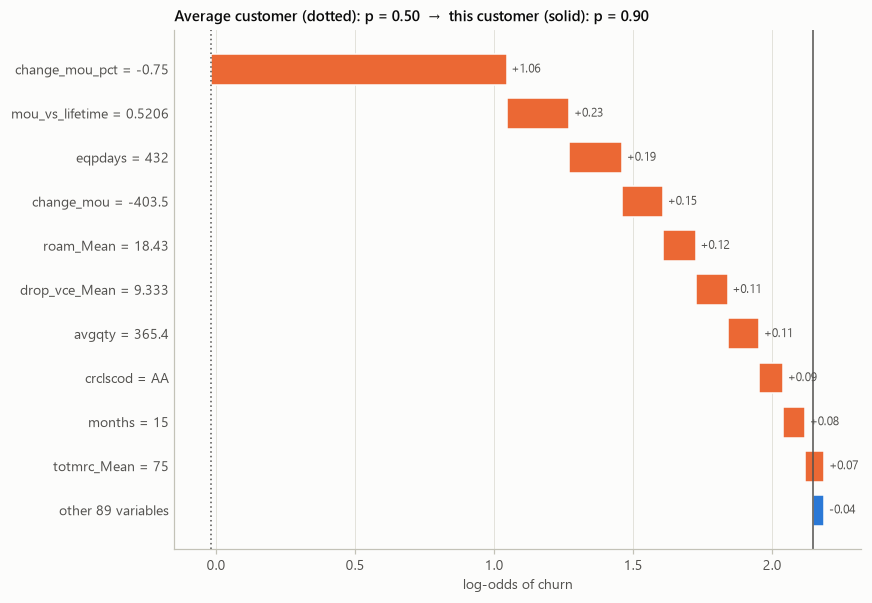

In [6]:
p = pd.Series(proba, index=X_test.index)
customer = (p - p.quantile(0.99)).abs().idxmin()
print(f"predicted churn probability {p[customer]:.2f}; churned: {bool(y_test[customer])}")
fig = plot_waterfall(contrib.loc[customer], values.loc[customer], base)

**Cosa dice.** Questo cliente ha probabilità 0.90 (ed è davvero andato via); il cliente medio parte da 0.50.
- Il grosso del rischio è **un crollo d'uso**: questo mese usa il 75% in meno della media degli ultimi 3 mesi
  (`change_mou_pct` = −0.75: +1.06 da solo, odds ×2.9) e circa metà del suo uso abituale (`mou_vs_lifetime` = 0.52,
  +0.23). Anche la differenza grezza in minuti (`change_mou`, +0.15) va nella stessa direzione.
- Si aggiungono un telefono oltre il gradino dei 300 giorni (432 giorni, +0.19), roaming e chiamate cadute (+0.11–0.12).
- Lo score diventa un motivo, e il motivo suggerisce l'azione: qui una chiamata di retention sul calo d'uso, prima
  che arrivi a zero, ed eventualmente un'offerta di cambio telefono.

## 4. La soglia: recall massima con precision ≥ 0.6

Il modello dà una probabilità; la soglia decide chi entra nella lista. **Il tuning non ottimizza la recall**: Optuna
massimizza la PR-AUC, cioè quanto bene il modello *ordina* i clienti, a prescindere dalla soglia. La recall si sceglie
con la soglia, nello script di training (`recall_threshold` in `train_xgboost.py`):

1. **Predizioni out-of-fold sul train**: ogni cliente di train riceve lo score di un modello addestrato sugli altri 4
   fold, che non l'ha visto.
2. Si provano tutte le soglie e si tengono quelle con **precision ≥ 0.6** (`xgb.min_precision` in config): almeno 6
   clienti in lista su 10 fanno davvero churn.
3. Tra queste si prende **la più bassa**: abbassare la soglia mette più clienti in lista, quindi dà la recall più
   alta. Risultato: **0.4305**, con recall out-of-fold 0.78.
4. La soglia viene congelata in config (`xgb.final.threshold`) e la usa anche il DAG; sul test viene solo misurata.

Perché non 0.5: con il 49.6% di churner, segnalare tutti dà già precision 0.5; il vincolo a 0.6 chiede di fare
nettamente meglio del caso.

Il grafico è la stessa curva, ridisegnata sul test: per ogni soglia, recall (quota dei churner che finiscono nella
lista) contro precision (quota della lista che fa davvero churn). Il punto è la soglia scelta; la linea tratteggiata
è una lista casuale (precision = tasso di churn).

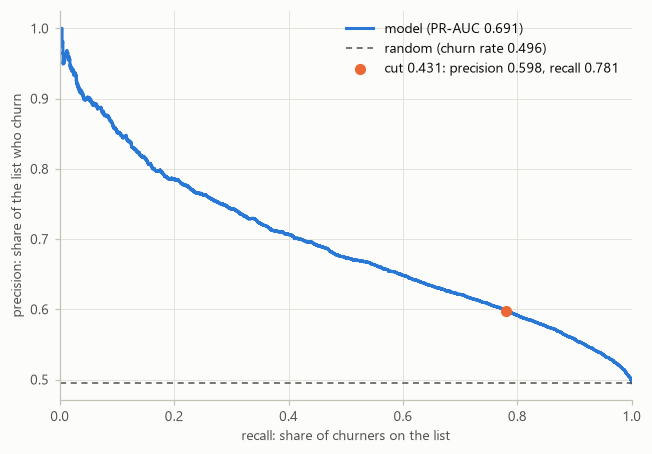

In [7]:
fig = plot_pr_curve(y_test, proba, threshold)

**Cosa dice.** Sul test la soglia dà **recall 0.78**, la stessa del train out-of-fold, e **precision 0.598**: 0.002
sotto il vincolo, una differenza da rumore (il vincolo è imposto sul train, il test non sceglie nulla). Più a sinistra
sulla curva la precision sale (0.80 sul 10% più a rischio, sezione 6), ma si trovano meno churner.

## 5. Risultati sull'hold-out: prima e dopo il cambio di soglia

Lo stesso modello e le stesse probabilità, con due soglie: **0.5**, quella di default, e **0.4305**, quella scelta
nella sezione 4. **PR-AUC e ROC-AUC sono uguali nelle due colonne**: misurano quanto bene il modello ordina i clienti,
e la soglia non cambia l'ordine. La soglia sposta solo precision, recall e F1, e la quota di clienti segnalati.

Nelle matrici di confusione le righe sono la verità (rimasto / churn) e le colonne la decisione del modello.

In [8]:
cuts = {"cut 0.5": cfg["model"]["threshold"], f"cut {threshold:.4f}": threshold}
table = pd.DataFrame({name: {**metrics(y_test, proba, cut), "flagged": (proba >= cut).mean()}
                      for name, cut in cuts.items()})
table.loc[["pr_auc", "roc_auc", "precision", "recall", "f1", "flagged"]].round(3)

,cut 0.5,cut 0.4305
pr_auc,0.691,0.691
roc_auc,0.699,0.699
precision,0.636,0.598
recall,0.640,0.781
f1,0.638,0.677
flagged,0.499,0.647


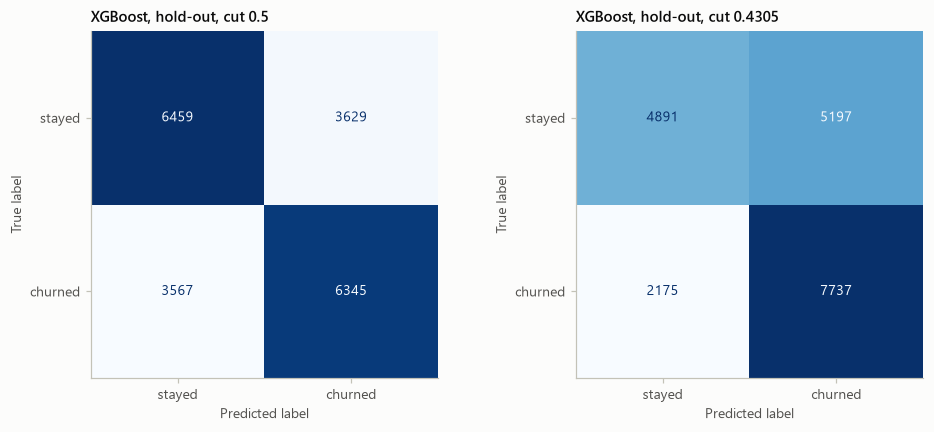

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (name, cut) in zip(axes, cuts.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, proba >= cut, display_labels=["stayed", "churned"], cmap="Blues",
                                            colorbar=False, ax=ax)
    ax.set_title(f"XGBoost, hold-out, {name}")
fig.tight_layout()

**Cosa dice.**
- **Soglia 0.5**: precision 0.64, recall 0.64, F1 0.64; il modello segnala metà dei clienti e trova 6345 churner
  su 9912.
- **Soglia 0.4305**: la lista sale al 65% dei clienti. I churner trovati salgono a **7737 (+1392, recall 0.78)**, ma
  entrano anche **1568 falsi allarmi in più** (5197 in tutto): la precision scende a 0.60, il limite del vincolo.
  F1 sale da 0.64 a 0.68.
- In pratica abbassare la soglia compra quasi un churner in più per ogni falso allarme in più (1392 contro 1568).
  Conviene se perdere un cliente costa più di una chiamata inutile, il caso tipico del churn.
- PR-AUC 0.691 e ROC-AUC 0.699 non cambiano: il modello è lo stesso, cambia solo chi entra nella lista.

## 6. Con un budget di chiamate: top 10% e top 20%

Alla soglia 0.43 il modello segnala 12934 clienti su 20000, ma un team retention ha un budget di chiamate. Allora si
ordinano i clienti per probabilità di churn e si chiamano i primi: qui il 10% (2000 chiamate) o il 20% (4000).
La domanda è: **quanti churner trovo con quelle chiamate, rispetto a chiamare a caso?** A caso, circa 5 chiamati su
10 sono churner (il tasso di churn del campione).

In [10]:
y = y_test.to_numpy()
ranked = y[np.argsort(-proba)]  # churn labels of the test customers, riskiest first
rows = {}
for share in (0.1, 0.2):
    k = int(share * len(ranked))
    rows[f"top {share:.0%}"] = {"clienti chiamati": k, "churner trovati": ranked[:k].sum(),
                                "churner con una lista casuale": round(k * y.mean()),
                                "quota di churner nella lista": ranked[:k].mean()}
pd.DataFrame(rows).T.astype({"clienti chiamati": int, "churner trovati": int,
                             "churner con una lista casuale": int}).round(2)

,clienti chiamati,churner trovati,churner con una lista casuale,quota di churner nella lista
top 10%,2000,1604,991,0.80
top 20%,4000,2971,1982,0.74


**Cosa dice.**
- **2000 chiamate**: 1604 churner trovati, 8 chiamati su 10, contro circa 990 (5 su 10) con una lista casuale:
  **circa 600 churner in più a parità di chiamate**.
- **4000 chiamate**: 2971 churner, 7.4 su 10, contro circa 1980 a caso: circa 1000 in più.
- Più la lista si allunga, più la quota scende: i primi della lista sono i casi più sicuri.

Vale la nota iniziale: sulla base reale, dove il churn è raro, sia la lista del modello sia quella casuale
conterrebbero meno churner.